# 05 · Random Survival Forest e comparação de modelos / RSF & model comparison

Compara os modelos em um **conjunto de teste** (25%, estratificado por evento e agrupado por `profile_id`).

> ⚠️ Uma única divisão com ~290 pessoas é ruidosa: diferenças de alguns centésimos no C-index
> podem ser sorte. A estimativa confiável está no **notebook 06** (validação cruzada repetida).


| Métrica | O que mede | Melhor |
|---|---|---|
| **C-index** (Harrell) | ordenação de risco: quem sai primeiro tem risco maior? | ↑ (0,5 = aleatório) |
| **Mean time-dependent AUC** | discriminação em cada horizonte $t$ | ↑ |
| **Integrated Brier Score** | calibração + discriminação das curvas $S(t\mid x)$ | ↓ |

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))  # works even without `pip install -e .`
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from turnover_survival import config, data, nonparametric, models, evaluation

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
T, E = config.DURATION_COL, config.EVENT_COL

df = data.load_clean()
print(f"{len(df)} employees | {df[E].sum()} left | {1 - df[E].mean():.1%} censored")

1116 employees | 560 left | 49.8% censored


In [2]:
X = data.make_design_matrix(df)
train, test = data.split(X)

cv = models.tune_cox_penalizer(train)
cph = models.fit_cox(train, penalizer=cv.iloc[0]["penalizer"])
aft = models.fit_aft_models(train)
rsf = models.fit_rsf_tuned(train)  # hyper-parameters tuned by inner grouped CV

## Comparação / Comparison

In [3]:
results = evaluation.evaluate(
    {"Cox PH": cph, **{f"{k} AFT": v for k, v in aft.items()}, "Random Survival Forest": rsf},
    train, test,
)
print(f"Kaplan-Meier (no covariates) IBS benchmark: {evaluation.km_baseline_ibs(train, test):.4f}")
results

Kaplan-Meier (no covariates) IBS benchmark: 0.2101


,model,c_index,mean_td_auc,integrated_brier
0,Weibull AFT,0.633,0.660,0.195
1,LogLogistic AFT,0.622,0.646,0.199
2,LogNormal AFT,0.620,0.643,0.199
3,Cox PH,0.620,0.647,0.198
4,Random Survival Forest,0.598,0.629,0.201


Um modelo só agrega valor se o **IBS** for menor que o benchmark de Kaplan-Meier sem covariáveis.

## Importância das variáveis (RSF) / Permutation importance

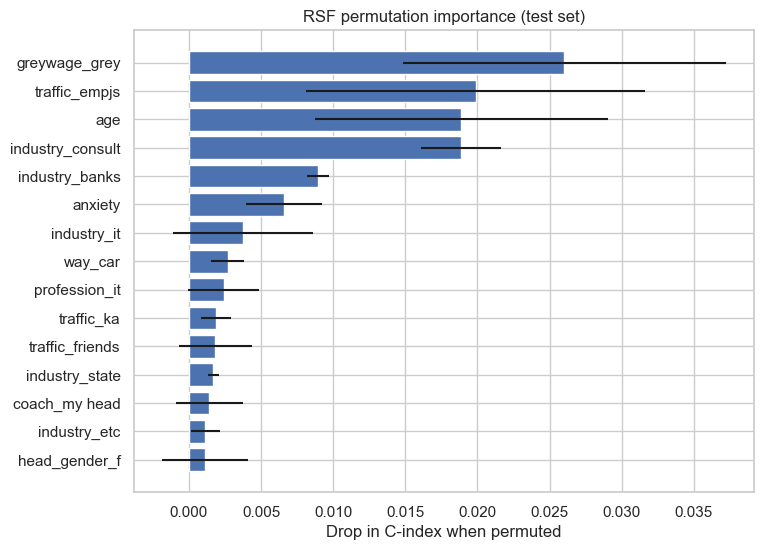

In [4]:
from sklearn.inspection import permutation_importance

Xt, yt = models.features(test), data.to_structured_y(test)
# n_jobs=1: the forest already predicts in parallel; nesting both stalls on Windows
pi = permutation_importance(rsf, Xt, yt, n_repeats=5, random_state=config.RANDOM_STATE, n_jobs=1)
imp = pd.DataFrame({"feature": Xt.columns, "importance": pi.importances_mean, "std": pi.importances_std})
imp = imp.sort_values("importance", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp["feature"][::-1], imp["importance"][::-1], xerr=imp["std"][::-1])
ax.set(xlabel="Drop in C-index when permuted", title="RSF permutation importance (test set)")
fig.savefig(config.FIGURES_DIR / "05_rsf_importance.png", dpi=120, bbox_inches="tight")

## Curvas individuais de retenção / Individual retention curves

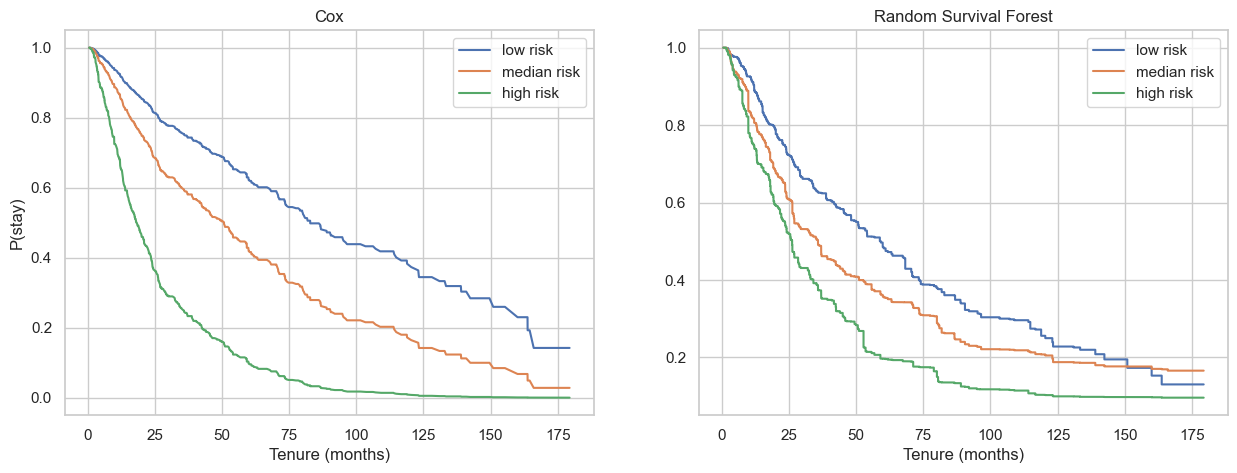

In [5]:
risk = cph.predict_partial_hazard(models.features(test))
picks = test.loc[[risk.idxmin(), risk.sort_values().index[len(risk) // 2], risk.idxmax()]]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cph.predict_survival_function(models.features(picks)).plot(ax=axes[0])
axes[0].set(title="Cox", xlabel="Tenure (months)", ylabel="P(stay)")
for fn, lab in zip(rsf.predict_survival_function(models.features(picks)), ["low risk", "median risk", "high risk"]):
    axes[1].step(fn.x, fn.y, where="post", label=lab)
axes[1].set(title="Random Survival Forest", xlabel="Tenure (months)")
axes[1].legend()
axes[0].legend(["low risk", "median risk", "high risk"])
fig.savefig(config.FIGURES_DIR / "05_individual_curves.png", dpi=120, bbox_inches="tight")

## Score de risco para RH / HR risk scoring

In [6]:
# probability of leaving within the next 12 months, for the test set
horizon = 12
p_leave = 1 - cph.predict_survival_function(models.features(test), times=[horizon]).T.iloc[:, 0]
scored = test[[T, E]].assign(p_leave_12m=p_leave.values,
                             risk_band=pd.qcut(p_leave.values, 3, labels=["low", "medium", "high"]))
scored.groupby("risk_band", observed=True).agg(n=(E, "size"), observed_turnover=(E, "mean"), mean_p=("p_leave_12m", "mean"))

,n,observed_turnover,mean_p
risk_band,,,
low,97,0.423,0.108
medium,98,0.480,0.140
high,97,0.629,0.192


> Observação: a probabilidade é **incondicional** (a partir da contratação). Para funcionários
> atuais, o correto é a probabilidade **condicional** ao tempo já cumprido:
> $P(T \le t+12 \mid T > t) = 1 - S(t+12)/S(t)$, via `cph.predict_survival_function(..., conditional_after=...)`.

### Conclusões / Takeaways
> _Preencha após rodar com os dados reais. / Fill in after running on the real data._